In [ ]:
# Nitsa Saint Fort
# 10/5/25
# CAP 4770
# Assignment 2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture as GMM
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import pairwise_kernels
from sklearn.decomposition import KernelPCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
from google.colab import drive

In [ ]:
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
path = 'drive/My Drive/mice-protein.csv'

In [ ]:
df=pd.read_csv(path)

1.1

In [ ]:
df.head()

,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m


In [ ]:
df = df.fillna(df.max())
print(df)

       MouseID  DYRK1A_N   ITSN1_N    BDNF_N     NR1_N    NR2A_N    pAKT_N  \
0        309_1  0.503644  0.747193  0.430175  2.816329  5.990152  0.218830   
1        309_2  0.514617  0.689064  0.411770  2.789514  5.685038  0.211636   
2        309_3  0.509183  0.730247  0.418309  2.687201  5.622059  0.209011   
3        309_4  0.442107  0.617076  0.358626  2.466947  4.979503  0.222886   
4        309_5  0.434940  0.617430  0.358802  2.365785  4.718679  0.213106   
...        ...       ...       ...       ...       ...       ...       ...   
1075  J3295_11  0.254860  0.463591  0.254860  2.092082  2.600035  0.211736   
1076  J3295_12  0.272198  0.474163  0.251638  2.161390  2.801492  0.251274   
1077  J3295_13  0.228700  0.395179  0.234118  1.733184  2.220852  0.220665   
1078  J3295_14  0.221242  0.412894  0.243974  1.876347  2.384088  0.208897   
1079  J3295_15  0.302626  0.461059  0.256564  2.092790  2.594348  0.251001   

       pBRAF_N  pCAMKII_N   pCREB_N  ...   pCFOS_N     SYP_N  H

In [ ]:
data = df.iloc[:,1:-4]
data = data.fillna
print(data)

<bound method NDFrame.fillna of       DYRK1A_N   ITSN1_N    BDNF_N     NR1_N    NR2A_N    pAKT_N   pBRAF_N  \
0     0.503644  0.747193  0.430175  2.816329  5.990152  0.218830  0.177565   
1     0.514617  0.689064  0.411770  2.789514  5.685038  0.211636  0.172817   
2     0.509183  0.730247  0.418309  2.687201  5.622059  0.209011  0.175722   
3     0.442107  0.617076  0.358626  2.466947  4.979503  0.222886  0.176463   
4     0.434940  0.617430  0.358802  2.365785  4.718679  0.213106  0.173627   
...        ...       ...       ...       ...       ...       ...       ...   
1075  0.254860  0.463591  0.254860  2.092082  2.600035  0.211736  0.171262   
1076  0.272198  0.474163  0.251638  2.161390  2.801492  0.251274  0.182496   
1077  0.228700  0.395179  0.234118  1.733184  2.220852  0.220665  0.161435   
1078  0.221242  0.412894  0.243974  1.876347  2.384088  0.208897  0.173623   
1079  0.302626  0.461059  0.256564  2.092790  2.594348  0.251001  0.191811   

      pCAMKII_N   pCREB_N    pE

In [ ]:
# check missing values
missing = df.isnull().sum()
print(missing[missing > 0])

Series([], dtype: int64)


In [ ]:
y_true = df.iloc[:, -1]
k = y_true.nunique()
print(k)

8


1.2

In [ ]:
# Removing the catagorical values in the mice-protein dataset
data1 = df.select_dtypes(include=["number"])
data1 = data1.dropna()
data1 = data1.to_numpy()
print(data1)
print("Array dtype:", data1.dtype)
print("Any object cells:", (data1.dtype == object))

[[0.50364388 0.74719322 0.4301753  ... 0.13179003 0.1281856  1.67565235]
 [0.51461708 0.68906355 0.41177034 ... 0.13510297 0.1311187  1.74360965]
 [0.50918309 0.7302468  0.41830878 ... 0.13336183 0.12743108 1.92642659]
 ...
 [0.22869955 0.39517937 0.23411809 ... 0.22919311 0.35521305 1.43082502]
 [0.22124241 0.41289438 0.24397413 ... 0.25131651 0.36535319 1.40403123]
 [0.30262572 0.46105919 0.25656431 ... 0.25299481 0.36527803 1.37099946]]
Array dtype: float64
Any object cells: False


In [ ]:
# Clustering the data by using KMeans
kmeans = KMeans(n_clusters=k)
kmeans.fit(data1)
labels = kmeans.predict(data1)
print(silhouette_score(data1, labels))

0.1816241556744223


In [ ]:
s=5
for i in range(s):
  kmeans = KMeans(n_clusters = k, random_state = i, n_init = 10)
  kmeans.fit(data1)
  labels = kmeans.predict(data1)
  print(silhouette_score(data1, labels))

0.20308778160206564
0.2003365049704196
0.20151675732977511
0.20160910270185667
0.19877340905996754


1.3

In [ ]:
#Kernel K-means
def kernel_kmeans(data1, k, kernel='rbf', kernel_param=None, max_iter=200, tol=1e-3, random_state=0):

    rng = np.random.default_rng(random_state)
    n = data1.shape[0]

    # Build kernel matrix with parameter
    if kernel_param is not None:
        if kernel == 'rbf':
            K = pairwise_kernels(data1, metric=kernel, gamma=kernel_param)
        elif kernel == 'poly':
            K = pairwise_kernels(data1, metric=kernel, degree=int(kernel_param))
        elif kernel == 'sigmoid':
            K = pairwise_kernels(data1, metric=kernel, gamma=kernel_param)
        else:
            K = pairwise_kernels(data1, metric=kernel)
    else:
        K = pairwise_kernels(data1, metric=kernel)

    labels = rng.integers(0, k, size=n)
    obj_trace, move_trace = [], []

    for it in range(1, max_iter + 1):
        clusters = [np.where(labels == i)[0] for i in range(k)]
        sizes = np.array([len(idx) for idx in clusters], dtype=float)

        # Handle empty clusters by moving a random point in
        for i, sz in enumerate(sizes):
            if sz == 0:
                j = rng.integers(0, n)
                labels[j] = i
                clusters[i] = np.array([j])
                sizes[i] = 1.0

        # Precompute terms per algorithm 13.2
        sqnorm = np.zeros(k)
        avg_j_i = np.zeros((n, k))
        for i in range(k):
            idx = clusters[i]
            Ki = K[np.ix_(idx, idx)]
            ni = sizes[i]
            sqnorm[i] = Ki.sum() / (ni * ni)
            avg_j_i[:, i] = K[idx, :].sum(axis=0) / ni

        K_diag = np.diag(K)
        dists = sqnorm[None, :] - 2 * avg_j_i + K_diag[:, None]
        new_labels = np.argmin(dists, axis=1)

        moved = np.mean(new_labels != labels)
        move_trace.append(moved)
        labels = new_labels
        obj_trace.append(np.sum(dists[np.arange(n), labels]))

        if moved <= tol:
            return labels, it, {"objective": obj_trace, "moved": move_trace}

    return labels, max_iter, {"objective": obj_trace, "moved": move_trace}


In [ ]:
data1 = df.select_dtypes(include=["number"])
data1 = data1.dropna()
data1 = data1.to_numpy()
print(data1)
print("Array dtype:", data1.dtype)
print("Any object cells:", (data1.dtype == object))

[[0.50364388 0.74719322 0.4301753  ... 0.13179003 0.1281856  1.67565235]
 [0.51461708 0.68906355 0.41177034 ... 0.13510297 0.1311187  1.74360965]
 [0.50918309 0.7302468  0.41830878 ... 0.13336183 0.12743108 1.92642659]
 ...
 [0.22869955 0.39517937 0.23411809 ... 0.22919311 0.35521305 1.43082502]
 [0.22124241 0.41289438 0.24397413 ... 0.25131651 0.36535319 1.40403123]
 [0.30262572 0.46105919 0.25656431 ... 0.25299481 0.36527803 1.37099946]]
Array dtype: float64
Any object cells: False



KERNEL K-MEANS ON ORIGINAL 4D DATA


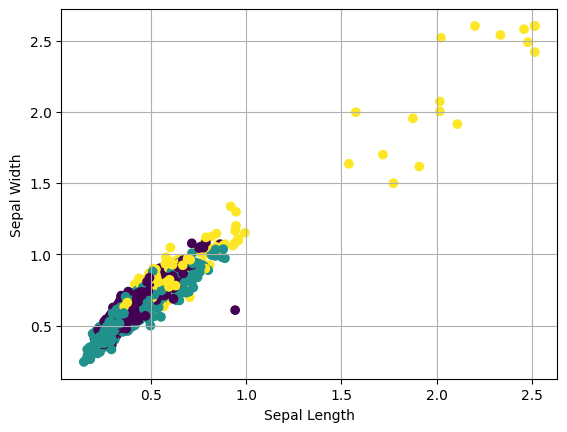

In [ ]:
print("\n" + "="*60)
print("KERNEL K-MEANS ON ORIGINAL 4D DATA")
print("="*60)

labels_linear, iters_linear, info_linear = kernel_kmeans(data1, k=3, kernel='linear', kernel_param=None, random_state=42)
# here I will plot the results based on sepal length and sepal width
plt.scatter(data1[:,0],data1[:,1],c=labels_linear)
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.grid()


Linear Kernel:
  Converged in 12 iterations
  Final objective: 3596.5454

Polynomial Kernel (degree=3):
  Converged in 15 iterations
  Final objective: 1002.0181


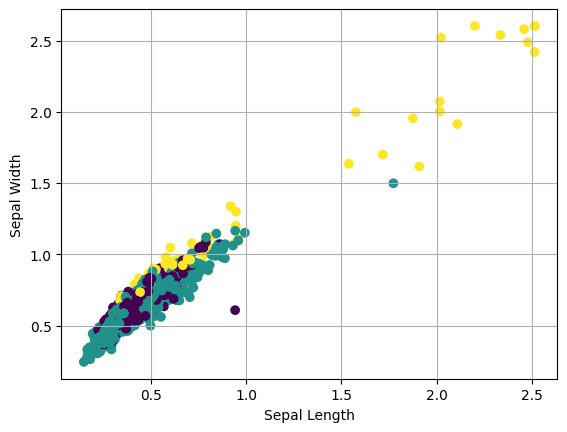

In [ ]:
print(f"\nLinear Kernel:")
print(f"  Converged in {iters_linear} iterations")
print(f"  Final objective: {info_linear['objective'][-1]:.4f}")

labels_poly, iters_poly, info_poly = kernel_kmeans(data1, k=3, kernel='poly', kernel_param=3, random_state=42
)
print(f"\nPolynomial Kernel (degree=3):")
print(f"  Converged in {iters_poly} iterations")
print(f"  Final objective: {info_poly['objective'][-1]:.4f}")

plt.scatter(data1[:,0],data1[:,1],c=labels_poly)
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.grid()


RBF Kernel (gamma=0.5):
  Converged in 11 iterations
  Final objective: 922.3252


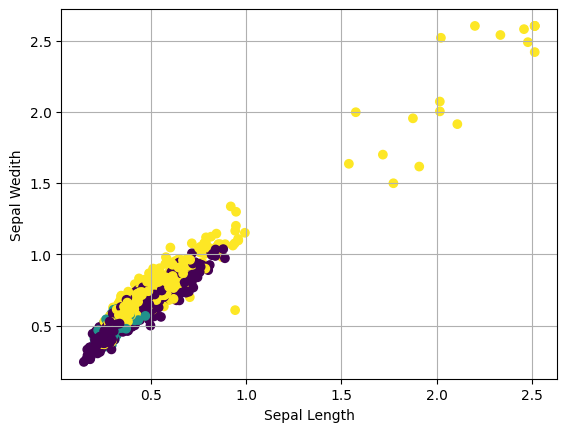

In [ ]:
labels_rbf, iters_rbf, info_rbf = kernel_kmeans(data1, k=3, kernel='rbf', kernel_param=0.5, random_state=42)
print(f"\nRBF Kernel (gamma=0.5):")
print(f"  Converged in {iters_rbf} iterations")
print(f"  Final objective: {info_rbf['objective'][-1]:.4f}")

plt.scatter(data1[:,0],data1[:,1],c=labels_rbf)
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Wedith')
plt.grid()

1.4

In [ ]:
# Gaussian Mixture on the mice-protein dataset
gmm = GMM(n_components = k)
gmm.fit(data1)
labels_gmm = gmm.predict(data1)
print(silhouette_score(data1, labels_gmm))

0.17126788730182363


In [ ]:
s = 5
for i in range(s):
  gmm = GMM(n_components = k, random_state = i, n_init = 10)
  gmm.fit(data1)
  labels_gmm = gmm.predict(data1)
  print(silhouette_score(data1, labels))

0.19877340905996754
0.19877340905996754
0.19877340905996754
0.19877340905996754
0.19877340905996754


In [ ]:
print(data1.shape)

(1080, 77)


In [ ]:
# using multiple seeds
s = 4
for i in range(s):
  kmeans = KMeans(n_clusters = k, random_state = i, n_init = 10)
  kmeans.fit(data1)
  labels = kmeans.predict(data1)
  print(silhouette_score(data1, labels))

0.20308778160206564
0.2003365049704196
0.20151675732977511
0.20160910270185667


In [ ]:
s = 7
for i in range(s):
  kmeans = KMeans(n_clusters = k, random_state = i, n_init = 10)
  kmeans.fit(data1)
  labels = kmeans.predict(data1)
  print(silhouette_score(data1, labels))

0.20308778160206564
0.2003365049704196
0.20151675732977511
0.20160910270185667
0.19877340905996754
0.20151675732977511
0.20327703697969046


1.5

The silhouette score from the Kmeans clustering is less than the silhouette score from the Gaussian Mixture Model.

1.6


PCA explained variance ratio: [0.42331635 0.27576215]
Total variance explained: 69.91%

KERNEL K-MEANS ON PCA 2D DATA

Linear Kernel:
  Converged in 10 iterations
  Final objective: 1735.5714

Polynomial Kernel (degree=3):
  Converged in 16 iterations
  Final objective: 51534.0299

RBF Kernel (gamma=0.5):
  Converged in 10 iterations
  Final objective: 621.2207


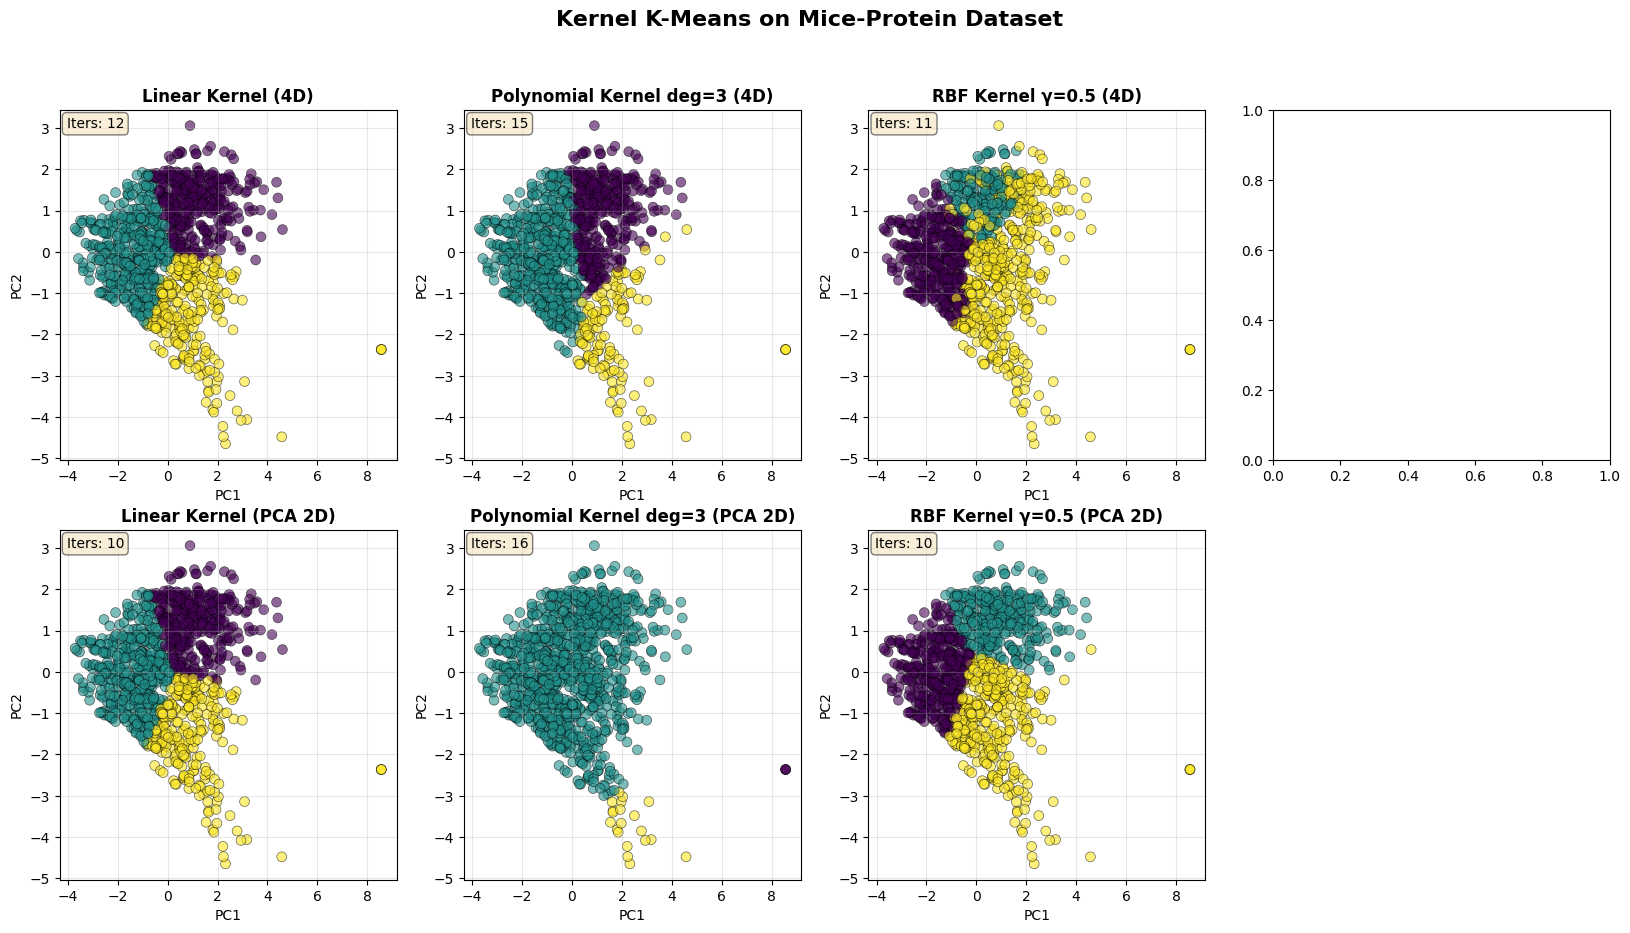


CLUSTER DISTRIBUTIONS

Linear (4D):
  Cluster 0: 333 samples
  Cluster 1: 476 samples
  Cluster 2: 271 samples

Poly (4D):
  Cluster 0: 357 samples
  Cluster 1: 590 samples
  Cluster 2: 133 samples

RBF (4D):
  Cluster 0: 374 samples
  Cluster 1: 202 samples
  Cluster 2: 504 samples

Linear (PCA):
  Cluster 0: 335 samples
  Cluster 1: 476 samples
  Cluster 2: 269 samples

Poly (PCA):
  Cluster 0: 3 samples
  Cluster 1: 1057 samples
  Cluster 2: 20 samples

RBF (PCA):
  Cluster 0: 372 samples
  Cluster 1: 335 samples
  Cluster 2: 373 samples


In [ ]:
pca = PCA(n_components=2)
D_pca = pca.fit_transform(data1)
print(f"\nPCA explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")
#=============================================================================#

# Apply kernel k-means on PCA-reduced 2D data
print("\n" + "="*60)
print("KERNEL K-MEANS ON PCA 2D DATA")
print("="*60)

labels_linear_pca, iters_linear_pca, info_linear_pca = kernel_kmeans(
    D_pca, k=3, kernel='linear', kernel_param=None, random_state=42
)
print(f"\nLinear Kernel:")
print(f"  Converged in {iters_linear_pca} iterations")
print(f"  Final objective: {info_linear_pca['objective'][-1]:.4f}")

labels_poly_pca, iters_poly_pca, info_poly_pca = kernel_kmeans(
    D_pca, k=3, kernel='poly', kernel_param=3, random_state=42
)
print(f"\nPolynomial Kernel (degree=3):")
print(f"  Converged in {iters_poly_pca} iterations")
print(f"  Final objective: {info_poly_pca['objective'][-1]:.4f}")

labels_rbf_pca, iters_rbf_pca, info_rbf_pca = kernel_kmeans(
    D_pca, k=3, kernel='rbf', kernel_param=0.5, random_state=42
)
print(f"\nRBF Kernel (gamma=0.5):")
print(f"  Converged in {iters_rbf_pca} iterations")
print(f"  Final objective: {info_rbf_pca['objective'][-1]:.4f}")

# Create visualization
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Kernel K-Means on Mice-Protein Dataset', fontsize=16, fontweight='bold')

# Map true labels to numeric
label_map = {label: i for i, label in enumerate(np.unique(y_true))}
y_numeric = np.array([label_map[label] for label in y_true])

# Top row: Results on original 4D data (visualized in 2D PCA space)
results_4d = [
    (labels_linear, 'Linear Kernel (4D)', info_linear),
    (labels_poly, 'Polynomial Kernel deg=3 (4D)', info_poly),
    (labels_rbf, 'RBF Kernel γ=0.5 (4D)', info_rbf)
]

for idx, (labels, title, info) in enumerate(results_4d):
    ax = axes[0, idx]
    scatter = ax.scatter(D_pca[:, 0], D_pca[:, 1], c=labels, cmap='viridis',
                        s=50, alpha=0.6, edgecolors='black', linewidth=0.5)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.grid(True, alpha=0.3)
    if info:
        ax.text(0.02, 0.98, f'Iters: {len(info["objective"])}',
                transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Bottom row: Results on PCA 2D data
results_pca = [
    (labels_linear_pca, 'Linear Kernel (PCA 2D)', info_linear_pca),
    (labels_poly_pca, 'Polynomial Kernel deg=3 (PCA 2D)', info_poly_pca),
    (labels_rbf_pca, 'RBF Kernel γ=0.5 (PCA 2D)', info_rbf_pca),
    (None, '', None)  # Empty plot
]

for idx, (labels, title, info) in enumerate(results_pca):
    ax = axes[1, idx]
    if labels is not None:
        scatter = ax.scatter(D_pca[:, 0], D_pca[:, 1], c=labels, cmap='viridis',
                            s=50, alpha=0.6, edgecolors='black', linewidth=0.5)
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('PC1')
        ax.set_ylabel('PC2')
        ax.grid(True, alpha=0.3)
        if info:
            ax.text(0.02, 0.98, f'Iters: {len(info["objective"])}',
                    transform=ax.transAxes, verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        ax.axis('off')

plt.show()

# Print cluster distributions
print("\n" + "="*60)
print("CLUSTER DISTRIBUTIONS")
print("="*60)

for name, labels in [
    ('Linear (4D)', labels_linear),
    ('Poly (4D)', labels_poly),
    ('RBF (4D)', labels_rbf),
    ('Linear (PCA)', labels_linear_pca),
    ('Poly (PCA)', labels_poly_pca),
    ('RBF (PCA)', labels_rbf_pca)
]:
    unique, counts = np.unique(labels, return_counts=True)
    print(f"\n{name}:")
    for cluster, count in zip(unique, counts):
        print(f"  Cluster {cluster}: {count} samples")


From the 2-D map, using the polynomial kernel for PCA shows an outlier of 1057 samples for Cluster 1. The RBF kernel for PCA shows the most consistent amount of samples for each of the 3 clusters.

2.1

In [ ]:
pca = PCA(n_components = 0.96)
pca.fit(data1)
data_red = pca.transform(data1)
print(data_red.shape)
# clustering the reduced data
kmeans = KMeans(n_clusters=k)
kmeans.fit(data1)
labels = kmeans.predict(data1)
print(silhouette_score(data1, labels))

(1080, 12)
0.19712921012106197


2.2

In [ ]:
# Clustering PCA with KMeans, Kernel KMeans, and Expectation Maximization
# KMeans
pca = PCA(n_components=30)
pca.fit(data1)
data_reduced = pca.transform(data1)
kmeans = KMeans(n_clusters=40)
kmeans.fit(data1)
y_kmeans = kmeans.predict(data1)
print(y_kmeans)
print(data_reduced.shape)

[20 38 38 ... 25 25  7]
(1080, 30)


In [ ]:
# EM
pca = PCA(n_components=30)
pca.fit(data1)
data_reduced = pca.transform(data1)
gmm = GMM(n_components=30)
gmm.fit(data_reduced)
y_gmm = gmm.predict(data_reduced)
print(y_gmm)

[23  4  4 ... 24 24 14]


In [ ]:
# Kernel KMeans
def kernel_kmeans(data1, k, kernel='rbf', kernel_param=None, max_iter=200, tol=1e-3, random_state=0):
    rng = np.random.default_rng(random_state)
    n = data1.shape[0]

    # Build kernel matrix with parameter
    if kernel_param is not None:
        if kernel == 'rbf':
            K = pairwise_kernels(data1, metric=kernel, gamma=kernel_param)
        elif kernel == 'poly':
            K = pairwise_kernels(data1, metric=kernel, degree=int(kernel_param))
        elif kernel == 'sigmoid':
            K = pairwise_kernels(data1, metric=kernel, gamma=kernel_param)
        else:
            K = pairwise_kernels(data1, metric=kernel)
    else:
        K = pairwise_kernels(data1, metric=kernel)

    labels = rng.integers(0, k, size=n)
    obj_trace, move_trace = [], []

    for it in range(1, max_iter + 1):
        clusters = [np.where(labels == i)[0] for i in range(k)]
        sizes = np.array([len(idx) for idx in clusters], dtype=float)

        # Handle empty clusters by moving a random point in
        for i, sz in enumerate(sizes):
            if sz == 0:
                j = rng.integers(0, n)
                labels[j] = i
                clusters[i] = np.array([j])
                sizes[i] = 1.0

        # Precompute terms per algorithm 13.2
        sqnorm = np.zeros(k)
        avg_j_i = np.zeros((n, k))
        for i in range(k):
            idx = clusters[i]
            Ki = K[np.ix_(idx, idx)]
            ni = sizes[i]
            sqnorm[i] = Ki.sum() / (ni * ni)
            avg_j_i[:, i] = K[idx, :].sum(axis=0) / ni

        K_diag = np.diag(K)
        dists = sqnorm[None, :] - 2 * avg_j_i + K_diag[:, None]
        new_labels = np.argmin(dists, axis=1)

        moved = np.mean(new_labels != labels)
        move_trace.append(moved)
        labels = new_labels
        obj_trace.append(np.sum(dists[np.arange(n), labels]))

        if moved <= tol:
            return labels, it, {"objective": obj_trace, "moved": move_trace}

    return labels, max_iter, {"objective": obj_trace, "moved": move_trace}

2.3

In [ ]:
# Kernel PCA with RBF kernel
def my_kpca(data1,k):
  mean1=np.mean(data1)
  data_centered=data1-mean1
  cov_matrix=np.cov(data_centered,rowvar=False)
  eig_values,eig_vectors=np.linalg.eig(cov_matrix)
  idx=np.argsort(eig_values)[:-1]
  eig_values=eig_values[idx]
  eig_vectors=eig_vectors[:,idx]
  reduced_eig_vectors = reduced_eig_vectors[:,:k]
  projected_data=np.dot(data_centered, reduced_eig_vectors)
  return projected_data,mean1,reduced_eig_vectors
RBF= 2(-1(x,y)^2/4x^2)
print(RBF)

SyntaxError: invalid decimal literal (ipython-input-3256010309.py, line 13)

2.4

In [ ]:
# Doing KMeans, Kernel KMeans, and EM with KPCA
# KMeans
kpca = KernelPCA(n_components=30)
kpca.fit(data1)
data_reduced = kpca.transform(data1)
kmeans = KMeans(n_clusters=40)
kmeans.fit(data1)
y_kmeans = kmeans.predict(data1)
print(y_kmeans)
print(data_reduced.shape)

[ 7 10 10 ... 37 37  1]
(1080, 30)


In [ ]:
# EM
kpca = KernelPCA(n_components=30)
kpca.fit(data1)
data_reduced = kpca.transform(data1)
gmm = GMM(n_components=30)
gmm.fit(data_reduced)
y_gmm = gmm.predict(data_reduced)
print(y_gmm)

[ 5 29 29 ... 23 23 23]



PCA explained variance ratio: [0.42331635 0.27576215]
Total variance explained: 69.91%

KERNEL K-MEANS ON KPCA 2D DATA

Linear Kernel:
  Converged in 10 iterations
  Final objective: 1735.5714

Polynomial Kernel (degree=3):
  Converged in 16 iterations
  Final objective: 51534.0299

RBF Kernel (gamma=0.5):
  Converged in 10 iterations
  Final objective: 621.2207


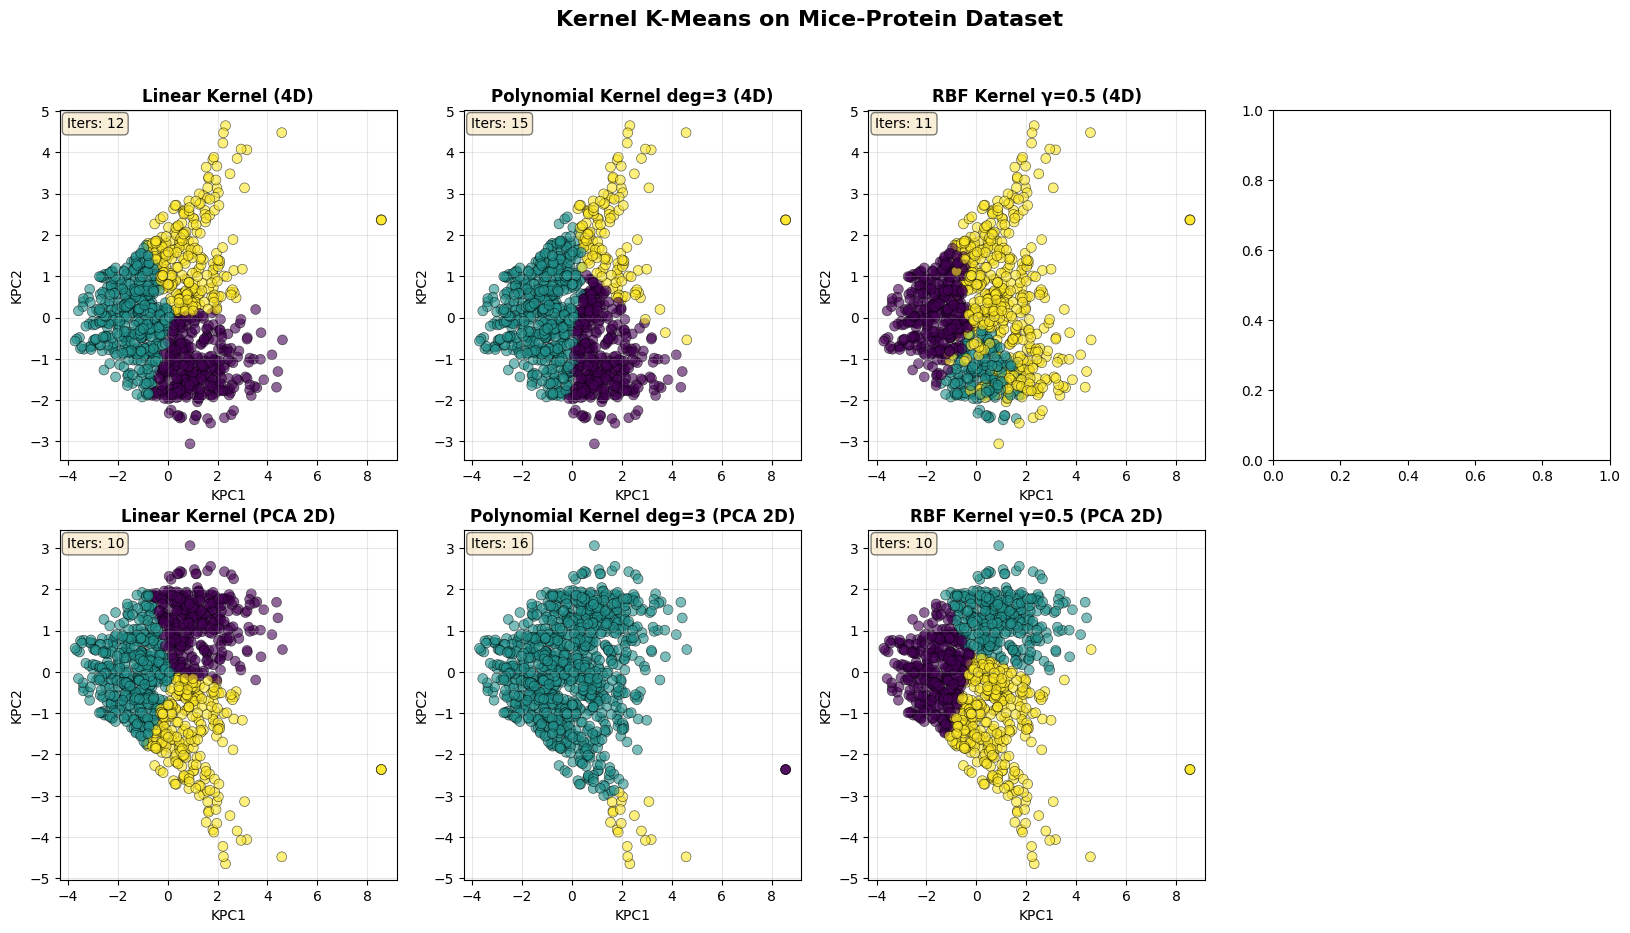


CLUSTER DISTRIBUTIONS

Linear (4D):
  Cluster 0: 333 samples
  Cluster 1: 476 samples
  Cluster 2: 271 samples

Poly (4D):
  Cluster 0: 357 samples
  Cluster 1: 590 samples
  Cluster 2: 133 samples

RBF (4D):
  Cluster 0: 374 samples
  Cluster 1: 202 samples
  Cluster 2: 504 samples

Linear (KPCA):
  Cluster 0: 335 samples
  Cluster 1: 476 samples
  Cluster 2: 269 samples

Poly (KPCA):
  Cluster 0: 3 samples
  Cluster 1: 1057 samples
  Cluster 2: 20 samples

RBF (KPCA):
  Cluster 0: 372 samples
  Cluster 1: 335 samples
  Cluster 2: 373 samples


In [ ]:
kpca = KernelPCA(n_components=2)
D_kpca = kpca.fit_transform(data1)
print(f"\nPCA explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")
#=============================================================================#

# Apply kernel k-means on KPCA-reduced 2D data
print("\n" + "="*60)
print("KERNEL K-MEANS ON KPCA 2D DATA")
print("="*60)

labels_linear_kpca, iters_linear_kpca, info_linear_kpca = kernel_kmeans(
    D_kpca, k=3, kernel='linear', kernel_param=None, random_state=42
)
print(f"\nLinear Kernel:")
print(f"  Converged in {iters_linear_kpca} iterations")
print(f"  Final objective: {info_linear_kpca['objective'][-1]:.4f}")

labels_poly_kpca, iters_poly_kpca, info_poly_kpca = kernel_kmeans(
    D_kpca, k=3, kernel='poly', kernel_param=3, random_state=42
)
print(f"\nPolynomial Kernel (degree=3):")
print(f"  Converged in {iters_poly_kpca} iterations")
print(f"  Final objective: {info_poly_kpca['objective'][-1]:.4f}")

labels_rbf_kpca, iters_rbf_kpca, info_rbf_kpca = kernel_kmeans(
    D_kpca, k=3, kernel='rbf', kernel_param=0.5, random_state=42
)
print(f"\nRBF Kernel (gamma=0.5):")
print(f"  Converged in {iters_rbf_kpca} iterations")
print(f"  Final objective: {info_rbf_kpca['objective'][-1]:.4f}")

# Create visualization
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Kernel K-Means on Mice-Protein Dataset', fontsize=16, fontweight='bold')

# Map true labels to numeric
label_map = {label: i for i, label in enumerate(np.unique(y_true))}
y_numeric = np.array([label_map[label] for label in y_true])

# Top row: Results on original 4D data (visualized in 2D KPCA space)
results_4d = [
    (labels_linear, 'Linear Kernel (4D)', info_linear),
    (labels_poly, 'Polynomial Kernel deg=3 (4D)', info_poly),
    (labels_rbf, 'RBF Kernel γ=0.5 (4D)', info_rbf)
]

for idx, (labels, title, info) in enumerate(results_4d):
    ax = axes[0, idx]
    scatter = ax.scatter(D_pca[:, 0], D_kpca[:, 1], c=labels, cmap='viridis',
                        s=50, alpha=0.6, edgecolors='black', linewidth=0.5)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('KPC1')
    ax.set_ylabel('KPC2')
    ax.grid(True, alpha=0.3)
    if info:
        ax.text(0.02, 0.98, f'Iters: {len(info["objective"])}',
                transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Bottom row: Results on KPCA 2D data
results_pca = [
    (labels_linear_kpca, 'Linear Kernel (PCA 2D)', info_linear_kpca),
    (labels_poly_kpca, 'Polynomial Kernel deg=3 (PCA 2D)', info_poly_kpca),
    (labels_rbf_kpca, 'RBF Kernel γ=0.5 (PCA 2D)', info_rbf_kpca),
    (None, '', None)  # Empty plot
]

for idx, (labels, title, info) in enumerate(results_pca):
    ax = axes[1, idx]
    if labels is not None:
        scatter = ax.scatter(D_pca[:, 0], D_pca[:, 1], c=labels, cmap='viridis',
                            s=50, alpha=0.6, edgecolors='black', linewidth=0.5)
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('KPC1')
        ax.set_ylabel('KPC2')
        ax.grid(True, alpha=0.3)
        if info:
            ax.text(0.02, 0.98, f'Iters: {len(info["objective"])}',
                    transform=ax.transAxes, verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        ax.axis('off')

plt.show()

# Print cluster distributions
print("\n" + "="*60)
print("CLUSTER DISTRIBUTIONS")
print("="*60)

for name, labels in [
    ('Linear (4D)', labels_linear),
    ('Poly (4D)', labels_poly),
    ('RBF (4D)', labels_rbf),
    ('Linear (KPCA)', labels_linear_pca),
    ('Poly (KPCA)', labels_poly_pca),
    ('RBF (KPCA)', labels_rbf_pca)
]:
    unique, counts = np.unique(labels, return_counts=True)
    print(f"\n{name}:")
    for cluster, count in zip(unique, counts):
        print(f"  Cluster {cluster}: {count} samples")


3.1
Based off Tasks 1 and 2, using KMeans without PCA with k clusters is most optimal pipeline because the silhouette score is around 20 percent which is greater than the other silhouette scores from the other pipelines.

3.2

In [ ]:
X=df.iloc[:,:8].to_numpy()
Y=df.iloc[:,8].to_numpy()
print(X.shape)
print(Y.shape)

(1080, 8)
(1080,)


In [ ]:
# Splitting the data into train and test
X_train, X_Test, y_train, y_test = train_test_split (X,Y,test_size=0.7)
print(X_train.shape)
print(X_Test.shape)
print(y_train.shape)
print(y_test.shape)
# Splitting the data into train and test
X_train, X_Test, y_train, y_test = train_test_split (X,Y,test_size=0.3)
print(X_train.shape)
print(X_Test.shape)
print(y_train.shape)
print(y_test.shape)

(324, 8)
(756, 8)
(324,)
(756,)
(756, 8)
(324, 8)
(756,)
(324,)


4.3 PCA is more helpful that KPCA when it comes to clustering because it has the right amount of data points used for clustering and it gives accurate information about what is happening in the mice-protein dataset. KPCA, especially with dimensionality reduction, does not use enough values to give a proper analysis on the data.

When doing this assignment, I noticed that the silhouette score was similar for each value I assigned to s. Also, when applying dimensionality reduction to PCA, I saw that the value for the silhouette score was randomized to either approximately 0.17, 0.18, 0.19, or 0.20. The matrices also gave randomized values when applying KMeans and EM to the data set.